# AI651 – Deep Learning for Space, Time and Graphs — PA3
**Roll number:** 24030023

In [1]:
import os, glob, time, math, json, platform, random, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT_DIR = '/kaggle/working/outputs' if os.path.isdir('/kaggle/working') else './outputs'
os.makedirs(OUT_DIR, exist_ok=True)

def savefig(fig, name):
    fig.savefig(os.path.join(OUT_DIR, name), dpi=150, bbox_inches='tight')

print('device:', DEVICE, '| outputs ->', OUT_DIR)

device: cuda | outputs -> /kaggle/working/outputs


## Hardware specification (Q7)

In [2]:
def hardware_info():
    info = {'python': platform.python_version(), 'torch': torch.__version__,
            'platform': platform.platform(), 'processor': platform.processor() or platform.machine(),
            'cpu_count': os.cpu_count(), 'device': str(DEVICE)}
    try:
        import psutil
        info['ram_GB'] = round(psutil.virtual_memory().total / 1e9, 1)
    except Exception:
        pass
    if torch.cuda.is_available():
        p = torch.cuda.get_device_properties(0)
        info['gpu'] = p.name; info['gpu_mem_GB'] = round(p.total_memory / 1e9, 1)
    return info
HW = hardware_info()
for k, v in HW.items(): print(f'{k:>12}: {v}')

      python: 3.13.16
       torch: 2.11.0+cu130
    platform: Linux-6.18.55+-x86_64-with-glibc2.39
   processor: x86_64
   cpu_count: 4
      device: cuda
      ram_GB: 33.7
         gpu: Tesla T4
  gpu_mem_GB: 15.6


# Question 1 – What does a sum remember?
### (a) Affine message

In [3]:
# Q1(a): numerical check that the affine-message aggregate collides for random w, c
N_a = [-1, +1]          # 0 steady neighbours
N_b = [0, 0]            # 2 steady neighbours
rng = np.random.default_rng(SEED)
for _ in range(5):
    w, c = rng.normal(size=2)
    agg = lambda nb: sum(w * x + c for x in nb)
    print(f'w={w:+.3f} c={c:+.3f} | agg(N_a)={agg(N_a):+.6f}  agg(N_b)={agg(N_b):+.6f}')
print('n, S for N_a:', len(N_a), sum(N_a), '| for N_b:', len(N_b), sum(N_b))

w=+0.305 c=-1.040 | agg(N_a)=-2.079968  agg(N_b)=-2.079968
w=+0.750 c=+0.941 | agg(N_a)=+1.881129  agg(N_b)=+1.881129
w=-1.951 c=-1.302 | agg(N_a)=-2.604359  agg(N_b)=-2.604359
w=+0.128 c=-0.316 | agg(N_a)=-0.632485  agg(N_b)=-0.632485
w=-0.017 c=-0.853 | agg(N_a)=-1.706088  agg(N_b)=-1.706088
n, S for N_a: 2 0 | for N_b: 2 0


### (b) Injective scalar message

In [4]:
# Q1(b): verify on every possible triple of trend counts with 1 <= n <= K
K = 8
B = K + 1
phi_b = {-1: 1, 0: B, +1: B**2}

nm, n0, npl = np.meshgrid(np.arange(K + 1), np.arange(K + 1), np.arange(K + 1), indexing='ij')
nm, n0, npl = nm.ravel(), n0.ravel(), npl.ravel()
tot = nm + n0 + npl
valid = (tot >= 1) & (tot <= K)
nm, n0, npl = nm[valid], n0[valid], npl[valid]

s = nm * phi_b[-1] + n0 * phi_b[0] + npl * phi_b[+1]
dec_m, dec_0, dec_p = s % B, (s // B) % B, s // B**2

print('number of valid count triples :', len(s))
print('number of distinct sums       :', len(np.unique(s)))
print('all sums distinct (injective) :', len(np.unique(s)) == len(s))
print('decoding recovers all counts  :', np.all(dec_m == nm) & np.all(dec_0 == n0) & np.all(dec_p == npl))

# simpler target: number of non-steady neighbours with phi(x) = x^2
from itertools import combinations_with_replacement as cwr
ok = all(sum(x**2 for x in nb) == sum(x != 0 for x in nb)
         for n in range(1, K + 1) for nb in cwr([-1, 0, 1], n))
print('phi(x)=x^2 counts non-steady neighbours for every neighbourhood:', ok)

number of valid count triples : 164
number of distinct sums       : 164
all sums distinct (injective) : True
decoding recovers all counts  : True
phi(x)=x^2 counts non-steady neighbours for every neighbourhood: True


### (c) Sum vs mean vs max with one-hot messages

In [5]:
from fractions import Fraction
from itertools import combinations_with_replacement as cwr

ONEHOT = {-1: (1, 0, 0), 0: (0, 1, 0), +1: (0, 0, 1)}
neighbourhoods = [nb for n in range(1, 9) for nb in cwr([-1, 0, 1], n)]

def agg(nb, method):
    msgs = np.array([ONEHOT[x] for x in nb])
    if method == 'Sum':  return tuple(int(v) for v in msgs.sum(0))
    if method == 'Mean': return tuple(Fraction(int(v), len(nb)) for v in msgs.sum(0))
    if method == 'Max':  return tuple(int(v) for v in msgs.max(0))

TASKS = {
    '(i) count steady':        lambda nb: sum(x == 0 for x in nb),
    '(ii) >half slowing':      lambda nb: sum(x == -1 for x in nb) > len(nb) / 2,
    '(iii) any slowing':       lambda nb: any(x == -1 for x in nb),
}

def fmt(v): return '(' + ', '.join(str(x) for x in v) + ')'

rows = []
for tname, task in TASKS.items():
    for method in ['Sum', 'Mean', 'Max']:
        seen, clash = {}, None
        for nb in neighbourhoods:
            a, ans = agg(nb, method), task(nb)
            if a in seen and seen[a][1] != ans:
                # prefer the shortest counter-example for readability
                cand = (seen[a][0], nb, a, seen[a][1], ans)
                if clash is None or len(cand[0]) + len(cand[1]) < len(clash[0]) + len(clash[1]):
                    clash = cand
            seen.setdefault(a, (nb, ans))
        if clash is None:
            rows.append((tname, method, 'Yes', ''))
        else:
            nb1, nb2, a, ans1, ans2 = clash
            rows.append((tname, method, 'No',
                         f'{list(nb1)} -> {fmt(a)} ans={ans1};  {list(nb2)} -> {fmt(a)} ans={ans2}'))

q1c = pd.DataFrame(rows, columns=['Task', 'Method', 'Possible?', 'Counter-example (if No)'])
pd.set_option('display.max_colwidth', None)
q1c

,Task,Method,Possible?,Counter-example (if No)
0,(i) count steady,Sum,Yes,
1,(i) count steady,Mean,No,"[0] -> (0, 1, 0) ans=1; [0, 0] -> (0, 1, 0) ans=2"
2,(i) count steady,Max,No,"[0] -> (0, 1, 0) ans=1; [0, 0] -> (0, 1, 0) ans=2"
3,(ii) >half slowing,Sum,Yes,
4,(ii) >half slowing,Mean,Yes,
5,(ii) >half slowing,Max,No,"[-1, 0] -> (1, 1, 0) ans=False; [-1, -1, 0] -> (1, 1, 0) ans=True"
6,(iii) any slowing,Sum,Yes,
7,(iii) any slowing,Mean,Yes,
8,(iii) any slowing,Max,Yes,


Decision rules for the **Yes** cells (aggregate $=(a_-,a_0,a_+)$):
- (i) Sum: $\rho$ returns $a_0$.
- (ii) Sum: $a_- > a_0 + a_+$. Mean: $a_- > 1/2$.
- (iii) Sum: $a_->0$. Mean: $a_->0$. Max: $a_-=1$.

# Question 2 – Which way is the slowdown moving?
### (a)(i) Symmetric layer, single-impulse fit

In [6]:
N_RING = 40
x0 = np.zeros(N_RING); x0[20] = 1.0
target = np.roll(x0, -1)                       # true next snapshot: x_i(t+1) = x_{i+1}(t)

def sym_features(x):                           # columns: x_i, x_{i-1}+x_{i+1}
    return np.stack([x, np.roll(x, 1) + np.roll(x, -1)], axis=1)

(a_fit, b_fit), *_ = np.linalg.lstsq(sym_features(x0), target, rcond=None)
pred = sym_features(x0) @ np.array([a_fit, b_fit])
print(f'least squares: a = {a_fit:.4f}, b = {b_fit:.4f}, SSE = {np.sum((pred - target)**2):.4f}')
print('pred at 19,20,21:', pred[19:22], '| target:', target[19:22])

least squares: a = 0.0000, b = 0.5000, SSE = 0.5000
pred at 19,20,21: [0.5 0.  0.5] | target: [1. 0. 0.]


### (a)(ii) Rolling out the fitted symmetric layer on a smooth bump

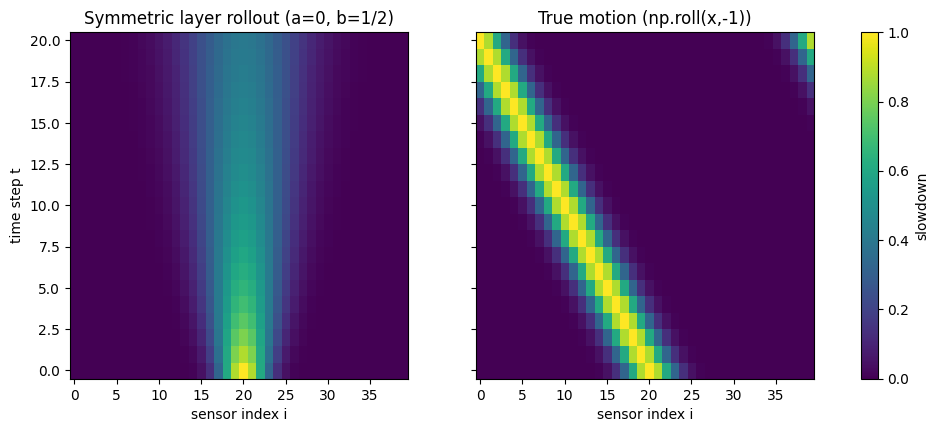

centre of mass  pred: t=0 20.00 -> t=20 20.00
peak height     pred: t=0 1.000 -> t=20 0.405
true peak location at t=20: 0


In [7]:
STEPS = 20
i_idx = np.arange(N_RING)
bump = np.exp(-(i_idx - 20)**2 / 8)

def sym_layer(x, a=a_fit, b=b_fit):
    return a * x + b * (np.roll(x, 1) + np.roll(x, -1))

pred_seq, true_seq = [bump.copy()], [bump.copy()]
for _ in range(STEPS):
    pred_seq.append(sym_layer(pred_seq[-1]))
    true_seq.append(np.roll(true_seq[-1], -1))
pred_seq, true_seq = np.array(pred_seq), np.array(true_seq)

vmin, vmax = min(pred_seq.min(), true_seq.min()), max(pred_seq.max(), true_seq.max())
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, seq, title in zip(axes, [pred_seq, true_seq], ['Symmetric layer rollout (a=0, b=1/2)', 'True motion (np.roll(x,-1))']):
    im = ax.imshow(seq, aspect='auto', origin='lower', cmap='viridis', vmin=vmin, vmax=vmax,
                   extent=[-0.5, N_RING - 0.5, -0.5, STEPS + 0.5])
    ax.set_xlabel('sensor index i'); ax.set_title(title)
axes[0].set_ylabel('time step t')
fig.colorbar(im, ax=axes, label='slowdown')
savefig(fig, 'q2a_heatmaps.png'); plt.show()

centre = lambda x: np.sum(i_idx * x) / np.sum(x)
print('centre of mass  pred: t=0 %.2f -> t=20 %.2f' % (centre(pred_seq[0]), centre(pred_seq[-1])))
print('peak height     pred: t=0 %.3f -> t=20 %.3f' % (pred_seq[0].max(), pred_seq[-1].max()))
print('true peak location at t=20:', true_seq[-1].argmax())

### (b) Direction-aware weights

In [8]:
x_rand = np.random.default_rng(0).normal(size=N_RING)
pred_b = 0 * x_rand + 0 * np.roll(x_rand, 1) + 1 * np.roll(x_rand, -1)
print('substitution exact on random snapshot:', np.allclose(pred_b, np.roll(x_rand, -1)))

conv = nn.Conv1d(1, 1, kernel_size=3, padding=1, padding_mode='circular', bias=False)
with torch.no_grad():
    conv.weight[:] = torch.tensor([[[0., 0., 1.]]])        # order: [x_{i-1}, x_i, x_{i+1}]
    out = conv(torch.tensor(x_rand, dtype=torch.float32).view(1, 1, -1)).view(-1).numpy()
print('Conv1d (circular padding) exact     :', np.allclose(out, np.roll(x_rand, -1), atol=1e-6))

substitution exact on random snapshot: True
Conv1d (circular padding) exact     : True


### (c) Adding history with symmetric neighbour weights

In [9]:
rng = np.random.default_rng(1)
a_c, b_c, c_c = 0.0, 1.0, -1.0
def hist_layer(x_t, x_prev):
    return a_c * x_t + b_c * (np.roll(x_t, 1) + np.roll(x_t, -1)) + c_c * x_prev

for name, step in [('backward  x_i(t+1)=x_{i+1}(t)', lambda x: np.roll(x, -1)),
                   ('forward   x_i(t+1)=x_{i-1}(t)', lambda x: np.roll(x, 1))]:
    ok = True
    for _ in range(100):
        x_prev = rng.normal(size=N_RING)
        x_t = step(x_prev); x_next = step(x_t)
        ok &= np.allclose(hist_layer(x_t, x_prev), x_next)
    print(f'{name}: exact for 100 random patterns -> {ok}')

# also roll the bump forward 20 steps with the history layer (backward motion)
seq = [bump, np.roll(bump, -1)]
for _ in range(STEPS - 1):
    seq.append(hist_layer(seq[-1], seq[-2]))
print('history-layer rollout matches true motion for 20 steps:', np.allclose(np.array(seq), true_seq))

backward  x_i(t+1)=x_{i+1}(t): exact for 100 random patterns -> True
forward   x_i(t+1)=x_{i-1}(t): exact for 100 random patterns -> True
history-layer rollout matches true motion for 20 steps: True


# Question 3 – Dataset preparation and graph construction
LargeST files used (Kaggle `liuxu77/largest`): `ca_his_raw_2020.h5`, `ca_his_raw_2021.h5` (5-min traffic flow, columns = sensor IDs), `ca_meta.csv` (sensor metadata) and `ca_rn_adj.npy` (road-network adjacency for all 8,600 CA sensors, rows ordered like `ca_meta.csv`). LargeST's SD subset = sensors in Caltrans **District 11** (716 sensors).

In [11]:
SEARCH_ROOTS = [os.environ.get('LARGEST_DIR', ''), '/kaggle/input', './data', '.']

def find_file(pattern, prefer=None):
    for root in SEARCH_ROOTS:
        if not root or not os.path.isdir(root):
            continue
        hits = sorted(glob.glob(os.path.join(root, '**', pattern), recursive=True))
        if prefer:
            hits = sorted(hits, key=lambda p: prefer not in os.path.basename(p))
        if hits:
            return hits[0]
    raise FileNotFoundError(f'{pattern} not found under {SEARCH_ROOTS}')

META_PATH = find_file('ca_meta.csv')
ADJ_PATH  = find_file('ca_rn_adj.npy')
HIS_PATH  = {y: find_file(f'*his*{y}*.h5', prefer='raw') for y in (2020, 2021)}
print(META_PATH, ADJ_PATH, HIS_PATH, sep='\n')

/kaggle/input/datasets/liuxu77/largest/ca_meta.csv
/kaggle/input/datasets/liuxu77/largest/ca_rn_adj.npy
{2020: '/kaggle/input/datasets/liuxu77/largest/ca_his_raw_2020.h5', 2021: '/kaggle/input/datasets/liuxu77/largest/ca_his_raw_2021.h5'}


In [12]:
def norm_id(v):
    if isinstance(v, bytes): v = v.decode()
    try:    return str(int(float(v)))
    except: return str(v).strip()

meta = pd.read_csv(META_PATH)
col = {c.lower(): c for c in meta.columns}
sd_mask = (meta[col['district']] == 11).values if 'district' in col else np.zeros(len(meta), bool)
if sd_mask.sum() != 716 and 'county' in col:
    sd_mask = meta[col['county']].astype(str).str.lower().str.contains('san diego').values
SD_POS = np.where(sd_mask)[0]                    # row positions in ca_meta == rows/cols of ca_rn_adj
sd_meta = meta.iloc[SD_POS].reset_index(drop=True)
SD_IDS = [norm_id(v) for v in sd_meta[col['id']]]
N = len(SD_IDS)
LAT = sd_meta[col['lat']].values.astype(float)
LNG = sd_meta[col.get('lng', col.get('lon', col.get('long')))].values.astype(float)
print('San Diego sensors:', N)
assert N == 716, 'expected 716 SD sensors'
sd_meta.head()

San Diego sensors: 716


,ID,Lat,Lng,District,County,Fwy,Lanes,Type,Direction,ID2
0,1114091,32.544463,-117.032486,11,San Diego,I5-N,6,Mainline,N,6931
1,1118333,32.551690,-117.045725,11,San Diego,I5-N,4,Mainline,N,6932
2,1118348,32.558459,-117.061845,11,San Diego,I5-N,4,Mainline,N,6933
3,1114720,32.561334,-117.067081,11,San Diego,I5-N,4,Mainline,N,6934
4,1118352,32.569052,-117.076507,11,San Diego,I5-N,4,Mainline,N,6935


### Q3(a) – Extraction (memory-efficient) and resampling

In [13]:
import h5py

def read_sd_year(path, ids, chunk=4096):
    # Read only the SD columns from a pandas 'fixed'-format HDF5 file, in row chunks,
    # so the full 8,600-sensor year never has to sit in memory.
    try:
        with h5py.File(path, 'r') as f:
            found = []
            f.visititems(lambda name, obj: found.append(obj.name)
                         if isinstance(obj, h5py.Group) and 'block0_values' in obj else None)
            g = f[found[0]]
            if 'block1_values' in g:
                raise ValueError('multi-block frame')
            cols = [norm_id(c) for c in g['block0_items'][:]]
            index = pd.to_datetime(g['axis1'][:])
            V = g['block0_values']
            if V.shape == (len(cols), len(index)):       # stored un-transposed
                raise ValueError('unexpected orientation')
            pos = {c: i for i, c in enumerate(cols)}
            cidx = np.array([pos[i] for i in ids])
            out = np.empty((V.shape[0], len(ids)), dtype=np.float32)
            for r in range(0, V.shape[0], chunk):
                out[r:r + chunk] = V[r:r + chunk][:, cidx]
        return pd.DataFrame(out, index=index, columns=ids)
    except Exception as e:
        print(f'  h5py fast path failed ({e}); falling back to pandas.read_hdf')
        df = pd.read_hdf(path)
        df.columns = [norm_id(c) for c in df.columns]
        return df[ids].astype(np.float32)

raw5 = {}
for y, p in HIS_PATH.items():
    t0 = time.time()
    df = read_sd_year(p, SD_IDS)
    df = df[df.index.year == y]
    full = pd.date_range(f'{y}-01-01 00:00', f'{y}-12-31 23:55', freq='5min')
    raw5[y] = df.reindex(full)                   # exposes missing timestamps as NaN
    print(f'{y}: {raw5[y].shape}  read in {time.time() - t0:.1f}s')
df5 = pd.concat([raw5[2020], raw5[2021]])
del raw5
print('5-min tensor:', df5.shape, '| range', df5.index.min(), '->', df5.index.max())
print(df5.iloc[:, :5].describe().T[['mean', 'min', 'max']])

2020: (105408, 716)  read in 26.8s
2021: (105120, 716)  read in 27.7s
5-min tensor: (210528, 716) | range 2020-01-01 00:00:00 -> 2021-12-31 23:55:00
               mean  min    max
1114091  138.889938  0.0  350.0
1118333   66.854843  0.0  188.0
1118348   74.815163  0.0  240.0
1114720  110.766632  0.0  290.0
1118352  111.876335  0.0  296.0


**Aggregation choice.** PeMS/LargeST "flow" is the number of vehicles counted in each 5-min interval (summed over lanes), i.e. an *interval count*, so 15-min values are **sums** of the three 5-min counts (units: vehicles / 15 min). When only some of the three 5-min values are present the sum is estimated as $3\times$ the mean of the available ones; an interval with no observations stays missing.

missing 5-min values : 5.07%
missing 15-min values: 5.06%  (partially observed 15-min intervals: 0.02%)
zero-valued 15-min   : 0.14%
sensors with no data at all: 19 | sensors >50% missing: 43
15-min tensor: (70176, 716)


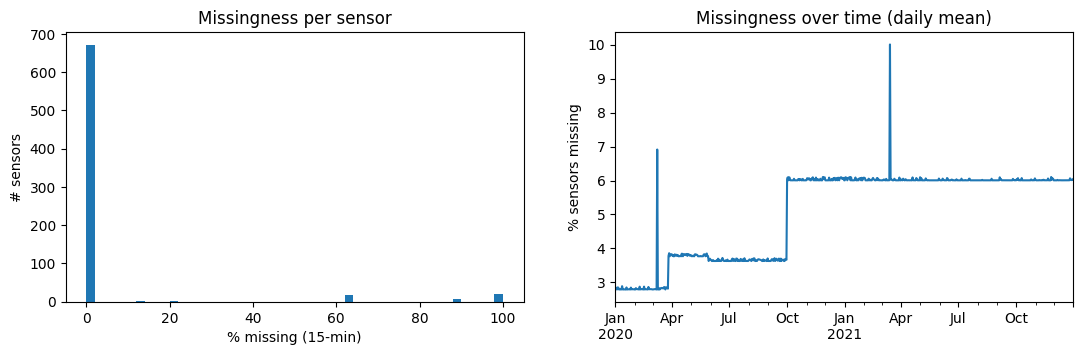

In [14]:
obs_cnt = df5.notna().astype(np.int8).resample('15min').sum()
df15 = df5.resample('15min').mean() * 3.0          # = sum of the 3 counts when all present
df15[obs_cnt == 0] = np.nan

miss5, miss15 = df5.isna().values.mean(), df15.isna().values.mean()
partial = ((obs_cnt > 0) & (obs_cnt < 3)).values.mean()
sensor_miss = df15.isna().mean()
print(f'missing 5-min values : {100 * miss5:.2f}%')
print(f'missing 15-min values: {100 * miss15:.2f}%  (partially observed 15-min intervals: {100 * partial:.2f}%)')
print(f'zero-valued 15-min   : {100 * (df15.values == 0).mean():.2f}%')
print('sensors with no data at all:', int((sensor_miss == 1).sum()), '| sensors >50% missing:', int((sensor_miss > .5).sum()))
print('15-min tensor:', df15.shape)
del df5

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].hist(100 * sensor_miss.values, bins=50); axes[0].set_xlabel('% missing (15-min)'); axes[0].set_ylabel('# sensors')
axes[0].set_title('Missingness per sensor')
df15.isna().mean(axis=1).resample('D').mean().mul(100).plot(ax=axes[1])
axes[1].set_ylabel('% sensors missing'); axes[1].set_title('Missingness over time (daily mean)')
savefig(fig, 'q3a_missing.png'); plt.show()

**Missing-value handling.**
1. A boolean mask `M` records which 15-min values were actually observed; it is used to **mask the loss and all metrics**, so models are never trained or scored on imputed targets.
2. Model *inputs* are imputed causally: forward-fill along time (only past values are used); leading NaNs at the very start of 2020 are back-filled (inside the training period), and sensors with no data at all are set to the training mean.

sensors with no observation at all: 19 -> filled with training mean 607.39
X: (70176, 716) NaNs left: 0


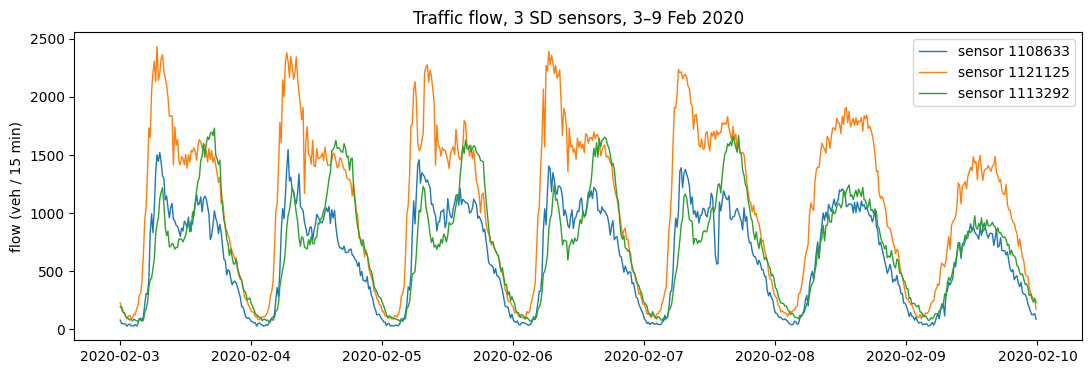

In [26]:
M_all = df15.notna().values                         # (T, N) observed mask
X_all = df15.ffill().bfill()
dead = X_all.columns[X_all.isna().all()]
train_fill = float(np.nanmean(df15.loc[df15.index.year == 2020].values))
print(f'sensors with no observation at all: {len(dead)} -> filled with training mean {train_fill:.2f}')
X_all = X_all.fillna(train_fill)
X_all = X_all.values.astype(np.float32)
TIMES = df15.index
T_total = len(TIMES)
print('X:', X_all.shape, 'NaNs left:', int(np.isnan(X_all).sum()))

# Q3(a).5 — three sensors over one week
plot_sensors = list(sensor_miss.sort_values().index[[0, 100, 300]])
week = slice('2020-02-03', '2020-02-09')
fig, ax = plt.subplots(figsize=(13, 4))
for s in plot_sensors:
    ax.plot(df15.loc[week, s].index, df15.loc[week, s].values, label=f'sensor {s}', lw=1)
ax.set_ylabel('flow (veh / 15 min)'); ax.set_title('Traffic flow, 3 SD sensors, 3–9 Feb 2020'); ax.legend()
savefig(fig, 'q3a_week.png'); plt.show()


### Q3(b) – Traffic graph

In [27]:
A_ca = np.load(ADJ_PATH, mmap_mode='r')
print('full CA adjacency:', A_ca.shape)
A_sd = np.asarray(A_ca[np.ix_(SD_POS, SD_POS)], dtype=np.float32)   # same ordering as SD_IDS / X_all columns
del A_ca

offdiag = ~np.eye(N, dtype=bool)
nz = (A_sd != 0)
print('nodes                     :', N)
print('nonzero entries (total)   :', int(nz.sum()))
print('nonzero self-loops (diag) :', int(np.diag(nz).sum()))
print('nonzero edges (off-diag)  :', int((nz & offdiag).sum()))
SYMMETRIC = np.allclose(A_sd, A_sd.T)
print('symmetric                 :', SYMMETRIC, '| structurally symmetric:', np.array_equal(nz, nz.T))
print('edge weight range         :', A_sd[nz & offdiag].min(), '->', A_sd[nz & offdiag].max())

full CA adjacency: (8600, 8600)
nodes                     : 716
nonzero entries (total)   : 18035
nonzero self-loops (diag) : 716
nonzero edges (off-diag)  : 17319
symmetric                 : False | structurally symmetric: False
edge weight range         : 0.010001835 -> 0.9999999


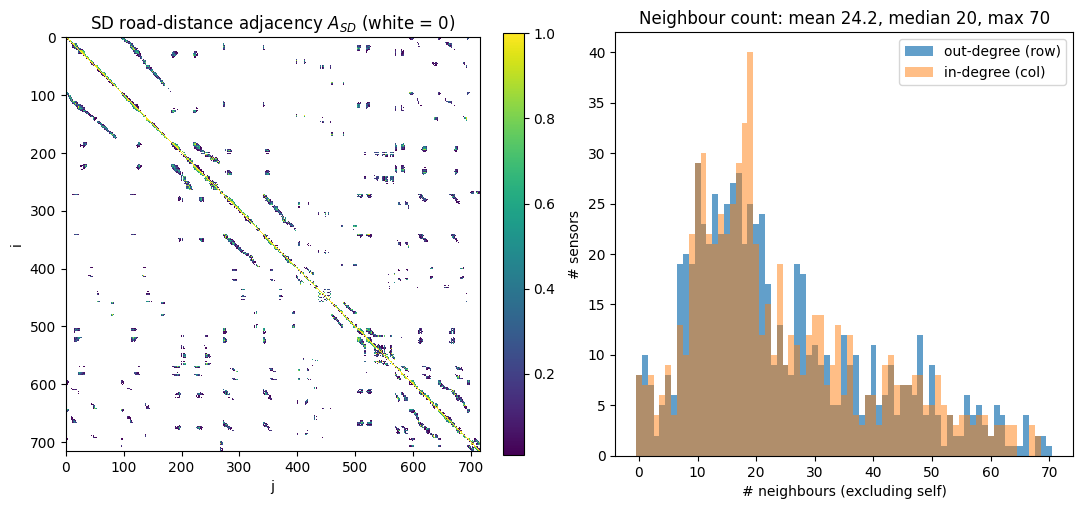

isolated sensors (no neighbours): 8


In [28]:
deg_out = (nz & offdiag).sum(1)
deg_in = (nz & offdiag).sum(0)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
im = axes[0].imshow(np.where(nz, A_sd, np.nan), cmap='viridis', interpolation='nearest')
axes[0].set_title('SD road-distance adjacency $A_{SD}$ (white = 0)'); axes[0].set_xlabel('j'); axes[0].set_ylabel('i')
fig.colorbar(im, ax=axes[0], fraction=.046)
axes[1].hist(deg_out, bins=np.arange(deg_out.max() + 2) - .5, alpha=.7, label='out-degree (row)')
if not SYMMETRIC:
    axes[1].hist(deg_in, bins=np.arange(deg_in.max() + 2) - .5, alpha=.5, label='in-degree (col)')
axes[1].set_xlabel('# neighbours (excluding self)'); axes[1].set_ylabel('# sensors'); axes[1].legend()
axes[1].set_title(f'Neighbour count: mean {deg_out.mean():.1f}, median {np.median(deg_out):.0f}, max {deg_out.max()}')
savefig(fig, 'q3b_adjacency.png'); plt.show()
print('isolated sensors (no neighbours):', int((deg_out == 0).sum()))

### Q3(c) – One-hop / two-hop neighbourhoods

selected sensor: index 33, ID 1126411
1-hop neighbours (20): ['1114805', '1114035', '1108547', '1118707', '1117871', '1108615', '1117818', '1126426', '1114806', '1108711', '1108693', '1111514', '1113486', '1115356', '1115413', '1115432', '1115438', '1116574', '1115528', '1115517']
2-hop neighbourhood (<=2 edges): 73 sensors; new at hop 2: 53
  new at hop 2: ['1117748', '1113976', '1117741', '1108603', '1117835', '1117717', '1118078', '1108611', '1108613', '1114050', '1108617', '1118496', '1118521', '1108665', '1117683', '1108417', '1117734', '1108605', '1118702', '1108609', '1108728', '1114540', '1111551', '1115420', '1115426', '1111566', '1115444', '1116783', '1114546', '1115555', '1115565', '1111552', '1116165', '1115548', '1111540', '1115572', '1121818', '1114450', '1114457', '1113279', '1111539', '1108331', '1111520', '1121821', '1114463', '1111509', '1121288', '1116112', '1113460', '1108572', '1115921', '1108391', '1115929']


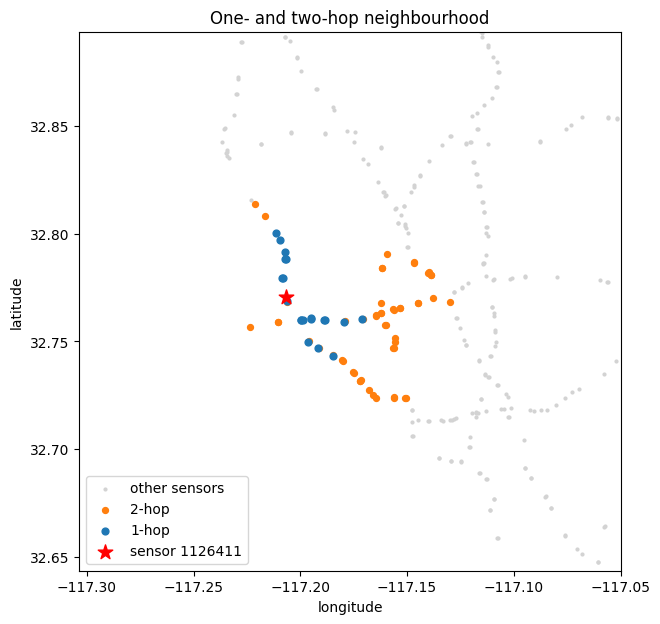

mean corr with 1-hop : 0.8980061782584245
mean corr with 2-hop : 0.9080568447818274
mean corr with random: 0.8840993104782086


/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [29]:
Bin = (nz & offdiag)
v = int(np.argsort(np.abs(deg_out - np.median(deg_out)) + 1e-3 * np.arange(N))[0])   # a typical (median-degree) sensor
one_hop = set(np.where(Bin[v])[0])
reach2 = (Bin.astype(np.int32) @ Bin.astype(np.int32))[v] > 0
two_hop_all = (one_hop | set(np.where(reach2)[0])) - {v}           # at most 2 edges
two_hop_only = two_hop_all - one_hop                                 # exactly 2 edges away
print(f'selected sensor: index {v}, ID {SD_IDS[v]}')
print(f'1-hop neighbours ({len(one_hop)}):', [SD_IDS[j] for j in sorted(one_hop)])
print(f'2-hop neighbourhood (<=2 edges): {len(two_hop_all)} sensors; new at hop 2: {len(two_hop_only)}')
print('  new at hop 2:', [SD_IDS[j] for j in sorted(two_hop_only)])

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(LNG, LAT, s=4, c='lightgrey', label='other sensors')
ax.scatter(LNG[list(two_hop_only)], LAT[list(two_hop_only)], s=18, c='tab:orange', label='2-hop')
ax.scatter(LNG[list(one_hop)], LAT[list(one_hop)], s=24, c='tab:blue', label='1-hop')
ax.scatter(LNG[v], LAT[v], s=120, c='red', marker='*', label=f'sensor {SD_IDS[v]}')
pad = .08
sel = list(two_hop_all | {v})
ax.set_xlim(LNG[sel].min() - pad, LNG[sel].max() + pad); ax.set_ylim(LAT[sel].min() - pad, LAT[sel].max() + pad)
ax.set_xlabel('longitude'); ax.set_ylabel('latitude'); ax.legend(); ax.set_title('One- and two-hop neighbourhood')
savefig(fig, 'q3c_neighbourhood.png'); plt.show()

# how strongly does the selected sensor correlate with its neighbours (training year)?
tr = TIMES.year == 2020
c = lambda j: np.corrcoef(X_all[tr, v], X_all[tr, j])[0, 1]
print('mean corr with 1-hop :', np.nanmean([c(j) for j in one_hop]))
print('mean corr with 2-hop :', np.nanmean([c(j) for j in two_hop_only]) if two_hop_only else 'n/a')
print('mean corr with random:', np.nanmean([c(j) for j in np.random.default_rng(0).choice(N, 50, replace=False) if j != v]))

# Question 4 – Spatio-temporal forecasting
### Q4(a) – Windows, splits and normalisation

In [30]:
T_IN, T_OUT = 8, 4
t_val  = int(np.searchsorted(TIMES, pd.Timestamp('2021-01-01')))
t_test = int(np.searchsorted(TIMES, pd.Timestamp('2021-04-01')))
SPLITS = {'train': (0, t_val), 'val': (t_val, t_test), 'test': (t_test, T_total)}

def window_ends(lo, hi):          # t such that t-7 >= lo and t+4 <= hi-1
    return np.arange(lo + T_IN - 1, hi - T_OUT)
ENDS = {k: window_ends(*v) for k, v in SPLITS.items()}

train_vals = X_all[:t_val][M_all[:t_val]]
MU, SIGMA = float(train_vals.mean()), float(train_vals.std())
del train_vals
for k, (lo, hi) in SPLITS.items():
    print(f'{k:5s}: {TIMES[lo]} -> {TIMES[hi - 1]} | {len(ENDS[k]):6d} windows')
print(f'train mean = {MU:.3f}, std = {SIGMA:.3f}')

# keep everything on the device and gather windows by indexing (no DataLoader overhead)
Xn_t = torch.tensor((X_all - MU) / SIGMA, dtype=torch.float32, device=DEVICE)   # (T, N)
assert not torch.isnan(Xn_t).any(), 'NaNs remain in the model inputs'
M_t = torch.tensor(M_all, device=DEVICE)
HIST = torch.arange(-T_IN + 1, 1, device=DEVICE)
FUT = torch.arange(1, T_OUT + 1, device=DEVICE)

def get_batch(ends):
    ends = torch.as_tensor(ends, device=DEVICE)
    x = Xn_t[ends[:, None] + HIST]          # (B, 8, N)
    y = Xn_t[ends[:, None] + FUT]           # (B, 4, N)
    m = M_t[ends[:, None] + FUT]            # (B, 4, N)
    return x, y, m

xb, yb, mb = get_batch(ENDS['train'][:2]); print('batch shapes:', xb.shape, yb.shape, mb.shape)


train: 2020-01-01 00:00:00 -> 2020-12-31 23:45:00 |  35125 windows
val  : 2021-01-01 00:00:00 -> 2021-03-31 23:45:00 |   8629 windows
test : 2021-04-01 00:00:00 -> 2021-12-31 23:45:00 |  26389 windows
train mean = 607.386, std = 483.770
batch shapes: torch.Size([2, 8, 716]) torch.Size([2, 4, 716]) torch.Size([2, 4, 716])


### Q4(b) – Model
- **Temporal encoder:** per sensor, temporal conv `(1→d, k=3)` → ReLU → temporal conv `(d→d, k=3)` → ReLU → flatten (d·8) → Linear → $Z\in\mathbb R^{B\times N\times d}$ (the convs are shared across sensors).
- **Graph convolution:** $H=\mathrm{ReLU}(\hat A Z W_g)$, multiplied over the node dimension for each batch item. A residual skip ($H \leftarrow H + Z$) is used so each sensor keeps its own temporal features even under a learned graph whose rows may not include the node itself; the temporal-only model is exactly this network with the graph branch removed.
- **Head:** MLP $d\to d\to 4$ per sensor.
- **Loss:** masked MAE on normalised values (only observed targets). Metrics are masked MAE / RMSE in original units (veh / 15 min).

In [31]:
HID = 32          # hidden dim d (16–32 for CPU feasibility)
EMB = 10          # node-embedding dim d_e for the adaptive graph
TOPK = 20         # keep top-k learned neighbours per node (None = dense)
RESIDUAL = True
EPOCHS, PATIENCE, BATCH, LR, WD, CLIP = 30, 5, 64, 1e-3, 1e-4, 5.0
EVAL_BATCH = 256

class TemporalConv(nn.Module):
    # 'same'-padded 1D convolution along time, written as unfold + matmul.
    # Mathematically identical to nn.Conv1d(cin, cout, k, padding=k//2) (checked below) but
    # ~15x faster on CPU for B*N = 45k very short (length-8) sequences.
    def __init__(self, cin, cout, k=3):
        super().__init__(); self.k = k; self.lin = nn.Linear(cin * k, cout)
    def forward(self, h):                       # h: (M, T, cin) -> (M, T, cout)
        hp = F.pad(h, (0, 0, self.k // 2, self.k // 2))
        return self.lin(hp.unfold(1, self.k, 1).flatten(2))

class TemporalEncoder(nn.Module):
    def __init__(self, t_in=T_IN, d=HID, k=3):
        super().__init__()
        self.conv1 = TemporalConv(1, d, k)
        self.conv2 = TemporalConv(d, d, k)
        self.proj = nn.Linear(d * t_in, d)
    def forward(self, x):                      # x: (B, T, N)
        B_, T_, N_ = x.shape
        h = x.permute(0, 2, 1).reshape(B_ * N_, T_, 1)
        h = F.relu(self.conv1(h))
        h = F.relu(self.conv2(h))
        z = F.relu(self.proj(h.flatten(1)))
        return z.view(B_, N_, -1)              # (B, N, d)

class GraphConv(nn.Module):
    def __init__(self, d=HID):
        super().__init__()
        self.W = nn.Linear(d, d, bias=False)
    def forward(self, Z, A):                    # Z: (B, N, d), A: (N, N)
        return F.relu(torch.einsum('nm,bmd->bnd', A, self.W(Z)))

class ForecastHead(nn.Module):
    def __init__(self, d=HID, t_out=T_OUT):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, d), nn.ReLU(), nn.Linear(d, t_out))
    def forward(self, H):                       # (B, N, d) -> (B, 4, N)
        return self.net(H).permute(0, 2, 1)

class STModel(nn.Module):
    def __init__(self, adj=None, d=HID, residual=RESIDUAL):
        super().__init__()
        self.encoder, self.adj, self.head, self.residual = TemporalEncoder(d=d), adj, ForecastHead(d=d), residual
        self.gconv = GraphConv(d) if adj is not None else None
    def forward(self, x):
        Z = self.encoder(x)
        if self.gconv is None:
            return self.head(Z)
        H = self.gconv(Z, self.adj())
        return self.head(H + Z if self.residual else H)

# sanity check: TemporalConv == nn.Conv1d
_c, _t = nn.Conv1d(4, 6, 3, padding=1), TemporalConv(4, 6)
with torch.no_grad():
    _t.lin.weight.copy_(_c.weight.reshape(6, -1)); _t.lin.bias.copy_(_c.bias)
    _h = torch.randn(5, T_IN, 4)
    assert torch.allclose(_c(_h.transpose(1, 2)).transpose(1, 2), _t(_h), atol=1e-5)
print('TemporalConv matches nn.Conv1d')

TemporalConv matches nn.Conv1d


### Adjacency modules (used in Q4 and Q5)
- **Fixed:** if $A$ is symmetric, $\hat A=D^{-1/2}(A+I)D^{-1/2}$. If it is directed, use the random-walk normalisation $\hat A=D_{out}^{-1}(A+I)$ (each row averages a node's out-neighbours; no symmetry needed). Stored as a buffer, so it never changes.
- **Adaptive:** $A=\mathrm{Softmax}_{row}(\mathrm{ReLU}(E_1E_2^\top))$ with trainable $E_1,E_2\in\mathbb R^{N\times d_e}$ (random init). **Top-k sparsification is applied before normalisation**: per row, scores outside the top-k are set to $-\infty$, so the softmax renormalises over the k kept entries. Gradients flow through the k kept scores into $E_1,E_2$; the top-k selection itself is a non-differentiable index choice and is recomputed every forward pass, so neighbours can change as embeddings move.
- **Hybrid:** $A=\alpha\,\tilde A_{fixed}+(1-\alpha)A_{adaptive}$ with $\tilde A_{fixed}=D_{out}^{-1}(A+I)$ (row-stochastic, the same normalisation as the softmax rows) and learnable $\alpha=\sigma(a)$ initialised at 0.5.

In [32]:
A_tilde = A_sd.copy()
np.fill_diagonal(A_tilde, 0.0)                 # drop any stored self-loops, then add exactly I
A_tilde += np.eye(N, dtype=np.float32)

def sym_norm(A):
    d = A.sum(1); dinv = 1 / np.sqrt(d)
    return (dinv[:, None] * A * dinv[None, :]).astype(np.float32)
def row_norm(A):
    return (A / A.sum(1, keepdims=True)).astype(np.float32)

A_FIXED_HAT = sym_norm(A_tilde) if SYMMETRIC else row_norm(A_tilde)
A_FIXED_ROW = row_norm(A_tilde)
print('fixed normalisation used:', 'D^-1/2 (A+I) D^-1/2' if SYMMETRIC else 'D_out^-1 (A+I)')

class FixedAdj(nn.Module):
    def __init__(self, A_hat):
        super().__init__(); self.register_buffer('A', torch.tensor(A_hat))
    def forward(self): return self.A

class AdaptiveAdj(nn.Module):
    def __init__(self, n=N, de=EMB, topk=TOPK):
        super().__init__()
        self.E1 = nn.Parameter(torch.randn(n, de) * 0.5)
        self.E2 = nn.Parameter(torch.randn(n, de) * 0.5)
        self.topk = topk
    def forward(self):
        S = F.relu(self.E1 @ self.E2.T)
        if self.topk is not None:
            vals, idx = S.topk(self.topk, dim=1)
            S = torch.full_like(S, float('-inf')).scatter(1, idx, vals)
        return torch.softmax(S, dim=1)

class HybridAdj(nn.Module):
    def __init__(self, A_fixed_row, n=N, de=EMB, topk=TOPK, alpha_init=0.5, learn_alpha=True):
        super().__init__()
        self.register_buffer('Af', torch.tensor(A_fixed_row))
        self.adaptive = AdaptiveAdj(n, de, topk)
        a0 = torch.logit(torch.tensor(alpha_init))
        self.a = nn.Parameter(a0) if learn_alpha else nn.Parameter(a0, requires_grad=False)
    @property
    def alpha(self): return torch.sigmoid(self.a)
    def forward(self): return self.alpha * self.Af + (1 - self.alpha) * self.adaptive()

fixed normalisation used: D_out^-1 (A+I)


In [46]:
def masked_mae(pred, y, m):
    err = torch.where(m, torch.abs(pred - y), torch.zeros_like(pred))   # NaN-safe masking
    return err.sum() / m.sum().clamp(min=1)

def sync():
    if DEVICE.type == 'cuda': torch.cuda.synchronize()

@torch.no_grad()
def evaluate(model, split, keep_nodes=None):
    model.eval()
    ae = torch.zeros(T_OUT, device=DEVICE); se = torch.zeros(T_OUT, device=DEVICE); cnt = torch.zeros(T_OUT, device=DEVICE)
    kept_pred, kept_true, kept_mask = [], [], []
    ends = ENDS[split]
    for i in range(0, len(ends), EVAL_BATCH):
        x, y, m = get_batch(ends[i:i + EVAL_BATCH])
        p = model(x) * SIGMA + MU
        yt = y * SIGMA + MU
        mf = m.float(); d = torch.where(m, p - yt, torch.zeros_like(p))
        ae += d.abs().sum((0, 2)); se += (d ** 2).sum((0, 2)); cnt += mf.sum((0, 2))
        if keep_nodes is not None:
            kept_pred.append(p[:, :, keep_nodes].cpu()); kept_true.append(yt[:, :, keep_nodes].cpu()); kept_mask.append(m[:, :, keep_nodes].cpu())
    res = {'MAE': (ae.sum() / cnt.sum()).item(), 'RMSE': torch.sqrt(se.sum() / cnt.sum()).item(),
           'MAE_h': (ae / cnt).tolist(), 'RMSE_h': torch.sqrt(se / cnt).tolist()}
    if keep_nodes is not None:
        res['pred'], res['true'], res['mask'] = torch.cat(kept_pred).numpy(), torch.cat(kept_true).numpy(), torch.cat(kept_mask).numpy()
    return res

def train_model(name, adj_factory):
    set_seed()
    model = STModel(adj=adj_factory()).to(DEVICE)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    # No weight decay on the graph parameters (E1, E2, alpha): with Adam, L2 decay drives the
    # embeddings to 0, where ReLU(E1 E2^T) = 0 has zero gradient and the learned graph collapses
    # to uniform 1/k weights. Weight decay is kept for the encoder / graph conv / head.
    graph_p = [p for n, p in model.named_parameters() if n.startswith('adj.') and p.requires_grad]
    other_p = [p for n, p in model.named_parameters() if not n.startswith('adj.') and p.requires_grad]
    groups = [{'params': other_p, 'weight_decay': WD}] + ([{'params': graph_p, 'weight_decay': 0.0}] if graph_p else [])
    opt = torch.optim.Adam(groups, lr=LR)
    g = torch.Generator().manual_seed(SEED)
    train_ends = torch.as_tensor(ENDS['train'])
    best, best_state, bad, hist = float('inf'), copy.deepcopy(model.state_dict()), 0, []
    sync(); t0 = time.time()
    for ep in range(1, EPOCHS + 1):
        model.train(); te = time.time(); tot = 0.0; nb = 0
        perm = train_ends[torch.randperm(len(train_ends), generator=g)]
        for i in range(0, len(perm), BATCH):
            x, y, m = get_batch(perm[i:i + BATCH])
            loss = masked_mae(model(x), y, m)
            if not torch.isfinite(loss):
                raise RuntimeError(f'[{name}] non-finite loss at epoch {ep} - check for NaNs in the inputs (Xn_t has {torch.isnan(Xn_t).sum().item()} NaNs)')
            opt.zero_grad(set_to_none=True); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), CLIP); opt.step()
            tot += loss.item(); nb += 1
        v = evaluate(model, 'val')
        hist.append({'epoch': ep, 'train_loss': tot / nb, 'val_MAE': v['MAE'], 'val_RMSE': v['RMSE']})
        msg = f'[{name}] ep {ep:2d} | train {tot / nb:.4f} | val MAE {v["MAE"]:.3f} RMSE {v["RMSE"]:.3f} | {time.time() - te:.1f}s'
        if hasattr(model.adj, 'alpha'): msg += f' | alpha {model.adj.alpha.item():.3f}'
        ad = model.adj.adaptive if hasattr(model.adj, 'adaptive') else (model.adj if hasattr(model.adj, 'E1') else None)
        if ad is not None:   # collapse monitor: scores should stay spread out, not shrink to 0
            with torch.no_grad():
                S = ad.E1 @ ad.E2.T
                Aw = ad()[ad() > 0]
            msg += f' | score std {S.std().item():.3f}, >0 {(S > 0).float().mean().item():.2f}, A max {Aw.max().item():.3f}'
        print(msg)
        if v['MAE'] < best - 1e-4:
            best, best_state, bad = v['MAE'], copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE: print(f'[{name}] early stop at epoch {ep}'); break
    sync(); train_time = time.time() - t0
    model.load_state_dict(best_state)
    return model, {'train_time_s': train_time, 'epochs_run': ep, 'best_epoch': int(np.argmin([h['val_MAE'] for h in hist]) + 1),
                   'n_params': n_params, 'history': hist}

PLOT_NODES = None   # chosen below
RESULTS, MODELS = {}, {}

def run(name, adjacency, adj_factory):
    model, info = train_model(name, adj_factory)
    val, test = evaluate(model, 'val'), evaluate(model, 'test', keep_nodes=PLOT_NODES)
    RESULTS[name] = {'adjacency': adjacency, 'val': val, 'test': test, **info}
    MODELS[name] = model
    print(f'==> {name}: val MAE {val["MAE"]:.3f} RMSE {val["RMSE"]:.3f} | test MAE {test["MAE"]:.3f} RMSE {test["RMSE"]:.3f} | '
          f'train time {info["train_time_s"]:.1f}s ({info["epochs_run"]} epochs, {info["n_params"]} params)')
    print('    test MAE per horizon (15/30/45/60 min):', np.round(test['MAE_h'], 3))


In [47]:
# sensors used for predicted-vs-actual plots: three well-observed test sensors
test_lo = SPLITS['test'][0]
test_obs = M_all[test_lo:].mean(0)
PLOT_NODES = [int(i) for i in np.argsort(-test_obs)[[0, 50, 150]]]
print('plot sensors:', [SD_IDS[i] for i in PLOT_NODES])

# naive reference: repeat last observed value
@torch.no_grad()
def eval_last_value(split):
    ae = se = cnt = 0.0
    for i in range(0, len(ENDS[split]), EVAL_BATCH):
        x, y, m = get_batch(ENDS[split][i:i + EVAL_BATCH])
        p = x[:, -1:, :].expand_as(y) * SIGMA + MU; yt = y * SIGMA + MU
        d = torch.where(m, p - yt, torch.zeros_like(p))
        ae += d.abs().sum().item(); se += (d ** 2).sum().item(); cnt += m.sum().item()
    return ae / cnt, math.sqrt(se / cnt)
print('last-value baseline  val MAE/RMSE: %.3f / %.3f' % eval_last_value('val'))
print('last-value baseline test MAE/RMSE: %.3f / %.3f' % eval_last_value('test'))


plot sensors: ['1108635', '1122951', '1108691']
last-value baseline  val MAE/RMSE: 81.224 / 125.283
last-value baseline test MAE/RMSE: 87.140 / 133.026


### Q4(b) / Q5(a) – STGNN with the fixed road-distance adjacency

In [48]:
run('STGNN-Fixed', 'Fixed', lambda: FixedAdj(A_FIXED_HAT))

[STGNN-Fixed] ep  1 | train 0.1676 | val MAE 59.193 RMSE 96.487 | 8.4s
[STGNN-Fixed] ep  2 | train 0.1195 | val MAE 58.342 RMSE 94.478 | 8.4s
[STGNN-Fixed] ep  3 | train 0.1172 | val MAE 57.297 RMSE 92.922 | 8.4s
[STGNN-Fixed] ep  4 | train 0.1155 | val MAE 56.949 RMSE 91.943 | 8.5s
[STGNN-Fixed] ep  5 | train 0.1149 | val MAE 56.971 RMSE 91.999 | 8.5s
[STGNN-Fixed] ep  6 | train 0.1140 | val MAE 56.294 RMSE 90.745 | 8.5s
[STGNN-Fixed] ep  7 | train 0.1133 | val MAE 55.680 RMSE 90.337 | 8.6s
[STGNN-Fixed] ep  8 | train 0.1129 | val MAE 56.715 RMSE 91.688 | 8.6s
[STGNN-Fixed] ep  9 | train 0.1130 | val MAE 56.487 RMSE 90.955 | 8.6s
[STGNN-Fixed] ep 10 | train 0.1119 | val MAE 55.277 RMSE 89.651 | 8.6s
[STGNN-Fixed] ep 11 | train 0.1115 | val MAE 55.497 RMSE 90.039 | 8.6s
[STGNN-Fixed] ep 12 | train 0.1114 | val MAE 55.212 RMSE 89.841 | 8.6s
[STGNN-Fixed] ep 13 | train 0.1110 | val MAE 54.645 RMSE 88.676 | 8.7s
[STGNN-Fixed] ep 14 | train 0.1106 | val MAE 54.895 RMSE 88.811 | 8.7s
[STGNN

### Q4(c) – Temporal-only baseline (same encoder and head, no graph convolution)

In [49]:
run('Temporal-only', 'None', lambda: None)

[Temporal-only] ep  1 | train 0.1739 | val MAE 61.264 RMSE 98.937 | 8.0s
[Temporal-only] ep  2 | train 0.1232 | val MAE 61.561 RMSE 98.577 | 8.0s
[Temporal-only] ep  3 | train 0.1222 | val MAE 60.231 RMSE 97.109 | 8.0s
[Temporal-only] ep  4 | train 0.1210 | val MAE 60.177 RMSE 96.815 | 8.0s
[Temporal-only] ep  5 | train 0.1206 | val MAE 59.174 RMSE 95.723 | 8.1s
[Temporal-only] ep  6 | train 0.1196 | val MAE 59.209 RMSE 95.550 | 8.1s
[Temporal-only] ep  7 | train 0.1194 | val MAE 58.813 RMSE 95.004 | 8.1s
[Temporal-only] ep  8 | train 0.1190 | val MAE 59.109 RMSE 95.505 | 8.1s
[Temporal-only] ep  9 | train 0.1190 | val MAE 59.268 RMSE 95.354 | 8.0s
[Temporal-only] ep 10 | train 0.1181 | val MAE 59.137 RMSE 94.457 | 8.0s
[Temporal-only] ep 11 | train 0.1181 | val MAE 59.262 RMSE 95.604 | 8.0s
[Temporal-only] ep 12 | train 0.1181 | val MAE 58.779 RMSE 94.914 | 8.0s
[Temporal-only] ep 13 | train 0.1174 | val MAE 58.231 RMSE 94.140 | 8.0s
[Temporal-only] ep 14 | train 0.1173 | val MAE 58.0

# Question 5 – Fixed vs learnable adjacency
### Q5(b) – Adaptive adjacency

In [50]:
run('STGNN-Adaptive', 'Adaptive', lambda: AdaptiveAdj())

[STGNN-Adaptive] ep  1 | train 0.1543 | val MAE 56.190 RMSE 92.026 | 9.8s | score std 0.847, >0 0.50, A max 0.560
[STGNN-Adaptive] ep  2 | train 0.1105 | val MAE 53.868 RMSE 87.412 | 9.8s | score std 0.977, >0 0.50, A max 0.908
[STGNN-Adaptive] ep  3 | train 0.1054 | val MAE 51.398 RMSE 83.030 | 9.8s | score std 1.036, >0 0.50, A max 0.909
[STGNN-Adaptive] ep  4 | train 0.1018 | val MAE 50.131 RMSE 80.924 | 9.8s | score std 1.075, >0 0.50, A max 0.846
[STGNN-Adaptive] ep  5 | train 0.0992 | val MAE 48.795 RMSE 79.390 | 9.8s | score std 1.110, >0 0.50, A max 0.820
[STGNN-Adaptive] ep  6 | train 0.0978 | val MAE 48.373 RMSE 78.384 | 9.8s | score std 1.140, >0 0.50, A max 0.822
[STGNN-Adaptive] ep  7 | train 0.0967 | val MAE 47.002 RMSE 77.134 | 9.8s | score std 1.165, >0 0.50, A max 0.829
[STGNN-Adaptive] ep  8 | train 0.0963 | val MAE 46.894 RMSE 77.018 | 9.8s | score std 1.187, >0 0.50, A max 0.838
[STGNN-Adaptive] ep  9 | train 0.0953 | val MAE 48.483 RMSE 77.418 | 9.8s | score std 1.

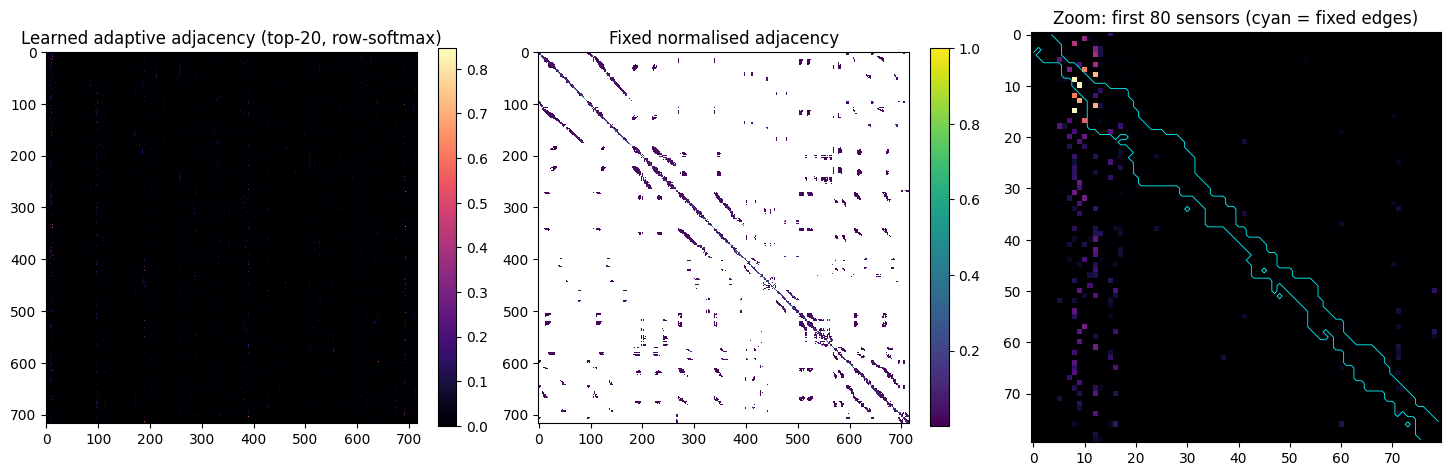

In [51]:
with torch.no_grad():
    A_learn = MODELS['STGNN-Adaptive'].adj().cpu().numpy()
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
im0 = axes[0].imshow(A_learn, cmap='magma', interpolation='nearest'); axes[0].set_title('Learned adaptive adjacency (top-%s, row-softmax)' % TOPK)
fig.colorbar(im0, ax=axes[0], fraction=.046)
im1 = axes[1].imshow(np.where(A_FIXED_HAT > 0, A_FIXED_HAT, np.nan), cmap='viridis', interpolation='nearest'); axes[1].set_title('Fixed normalised adjacency')
fig.colorbar(im1, ax=axes[1], fraction=.046)
z = slice(0, 80)
axes[2].imshow(A_learn[z, z], cmap='magma', interpolation='nearest'); axes[2].contour(A_FIXED_HAT[z, z] > 0, levels=[.5], colors='cyan', linewidths=.6)
axes[2].set_title('Zoom: first 80 sensors (cyan = fixed edges)')
savefig(fig, 'q5b_learned_adjacency.png'); plt.show()

### Q5(c) – Hybrid adjacency (learnable α)

In [52]:
run('STGNN-Hybrid', 'Hybrid', lambda: HybridAdj(A_FIXED_ROW))
print('learned alpha:', MODELS['STGNN-Hybrid'].adj.alpha.item())

[STGNN-Hybrid] ep  1 | train 0.1548 | val MAE 56.725 RMSE 91.998 | 9.9s | alpha 0.426 | score std 0.852, >0 0.50, A max 0.622
[STGNN-Hybrid] ep  2 | train 0.1116 | val MAE 55.930 RMSE 89.695 | 9.9s | alpha 0.289 | score std 1.020, >0 0.50, A max 0.847
[STGNN-Hybrid] ep  3 | train 0.1056 | val MAE 50.917 RMSE 82.320 | 9.9s | alpha 0.202 | score std 1.098, >0 0.50, A max 0.936
[STGNN-Hybrid] ep  4 | train 0.1018 | val MAE 49.268 RMSE 80.099 | 9.9s | alpha 0.155 | score std 1.135, >0 0.50, A max 0.930
[STGNN-Hybrid] ep  5 | train 0.0991 | val MAE 49.054 RMSE 79.153 | 9.9s | alpha 0.124 | score std 1.164, >0 0.50, A max 0.918
[STGNN-Hybrid] ep  6 | train 0.0979 | val MAE 48.974 RMSE 78.438 | 9.9s | alpha 0.104 | score std 1.188, >0 0.50, A max 0.900
[STGNN-Hybrid] ep  7 | train 0.0966 | val MAE 47.527 RMSE 77.296 | 9.9s | alpha 0.089 | score std 1.210, >0 0.50, A max 0.883
[STGNN-Hybrid] ep  8 | train 0.0962 | val MAE 47.266 RMSE 77.006 | 10.0s | alpha 0.078 | score std 1.228, >0 0.50, A m

# Question 6 – Experimental analysis
### Q6(a) – Comparison table

,Model,Adjacency,Val MAE,Val RMSE,Test MAE,Test RMSE,Training time (s),Epochs,Best epoch,Params
0,Temporal-only,None,58.050,93.947,65.641,103.933,152.726,19,14,12644
1,STGNN,Fixed,53.510,86.788,61.584,97.810,235.127,27,22,13668
2,STGNN,Adaptive,44.239,72.330,53.083,84.711,295.304,30,29,27988
3,STGNN,Hybrid,45.318,73.721,54.208,85.654,238.023,24,19,27989


Test MAE per horizon


,15 min,30 min,45 min,60 min
Temporal-only,45.373,59.664,72.233,85.295
STGNN-Fixed,43.323,56.022,67.508,79.485
STGNN-Adaptive,40.038,49.392,57.532,65.370
STGNN-Hybrid,40.441,50.157,59.365,66.868


Test RMSE per horizon


,15 min,30 min,45 min,60 min
Temporal-only,70.257,93.453,111.884,130.462
STGNN-Fixed,67.345,87.987,105.141,122.210
STGNN-Adaptive,62.751,78.428,90.745,101.885
STGNN-Hybrid,62.854,78.888,92.376,103.147


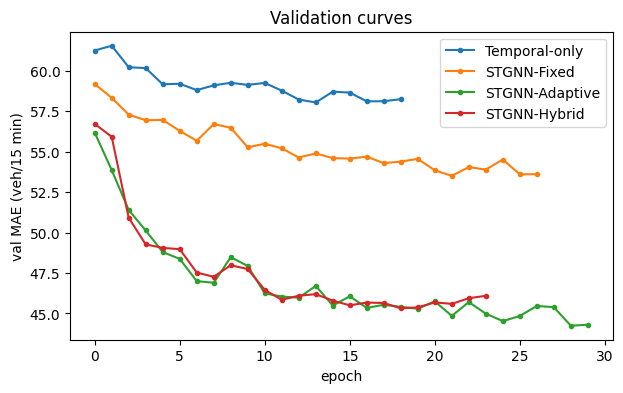

In [53]:
order = ['Temporal-only', 'STGNN-Fixed', 'STGNN-Adaptive', 'STGNN-Hybrid']
table = pd.DataFrame([{
    'Model': 'Temporal-only' if k == 'Temporal-only' else 'STGNN', 'Adjacency': RESULTS[k]['adjacency'],
    'Val MAE': RESULTS[k]['val']['MAE'], 'Val RMSE': RESULTS[k]['val']['RMSE'],
    'Test MAE': RESULTS[k]['test']['MAE'], 'Test RMSE': RESULTS[k]['test']['RMSE'],
    'Training time (s)': RESULTS[k]['train_time_s'], 'Epochs': RESULTS[k]['epochs_run'],
    'Best epoch': RESULTS[k]['best_epoch'], 'Params': RESULTS[k]['n_params']} for k in order])
table.to_csv(os.path.join(OUT_DIR, 'q6a_results.csv'), index=False)
display(table.round(3))

hz = pd.DataFrame({k: RESULTS[k]['test']['MAE_h'] for k in order}, index=['15 min', '30 min', '45 min', '60 min']).T
print('Test MAE per horizon'); display(hz.round(3))
hr = pd.DataFrame({k: RESULTS[k]['test']['RMSE_h'] for k in order}, index=['15 min', '30 min', '45 min', '60 min']).T
print('Test RMSE per horizon'); display(hr.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
for k in order:
    ax.plot([h['val_MAE'] for h in RESULTS[k]['history']], marker='o', ms=3, label=k)
ax.set_xlabel('epoch'); ax.set_ylabel('val MAE (veh/15 min)'); ax.legend(); ax.set_title('Validation curves')
savefig(fig, 'q6a_val_curves.png'); plt.show()

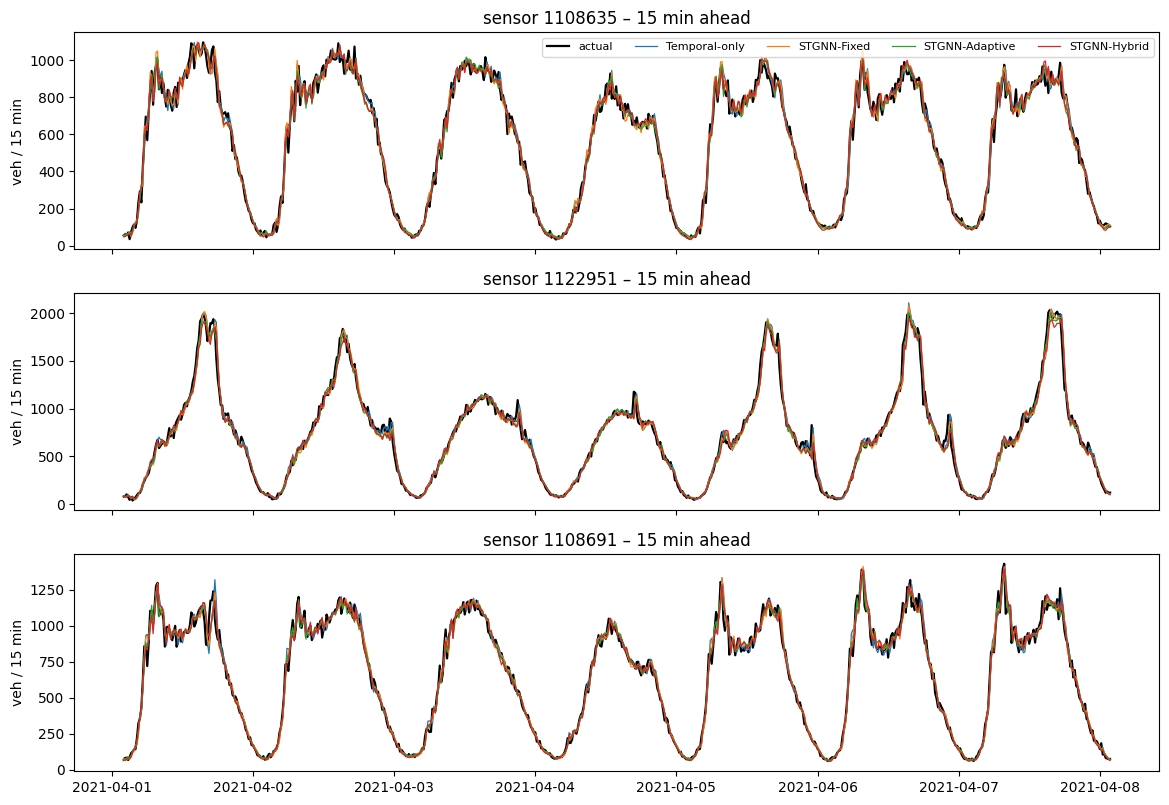

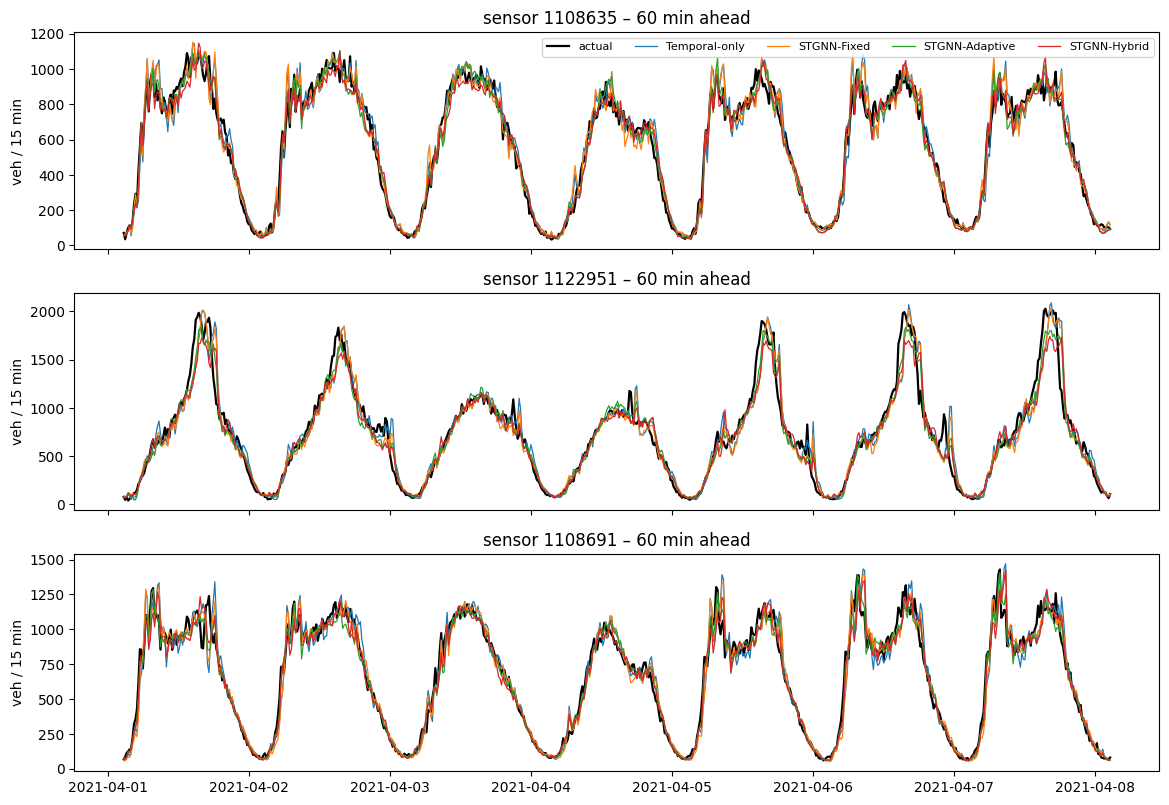

In [54]:
# predicted vs actual on the first test week, 15-min and 60-min ahead
WEEK = 7 * 96
ends_test = ENDS['test'][:WEEK]
for h_idx, h_name in [(0, '15 min ahead'), (3, '60 min ahead')]:
    fig, axes = plt.subplots(len(PLOT_NODES), 1, figsize=(14, 3.2 * len(PLOT_NODES)), sharex=True)
    t_axis = TIMES[ends_test + h_idx + 1]
    for r, node in enumerate(PLOT_NODES):
        ax = axes[r]
        true = RESULTS[order[0]]['test']['true'][:WEEK, h_idx, r].copy()
        true[~RESULTS[order[0]]['test']['mask'][:WEEK, h_idx, r]] = np.nan
        ax.plot(t_axis, true, color='black', lw=1.6, label='actual')
        for k in order:
            ax.plot(t_axis, RESULTS[k]['test']['pred'][:WEEK, h_idx, r], lw=.9, label=k)
        ax.set_ylabel('veh / 15 min'); ax.set_title(f'sensor {SD_IDS[node]} – {h_name}')
    axes[0].legend(ncol=5, fontsize=8)
    savefig(fig, f'q6a_pred_vs_actual_h{h_idx + 1}.png'); plt.show()

### Q6(b) – Graph structure analysis

In [55]:
from scipy.sparse.csgraph import shortest_path

def haversine_km(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, (lat1, lng1, lat2, lng2))
    a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

GEO = haversine_km(LAT[:, None], LNG[:, None], LAT[None, :], LNG[None, :])
HOPS = shortest_path((Bin | Bin.T).astype(np.float32), unweighted=True, directed=False)
CORR = np.corrcoef(X_all[:t_val].T)                    # training-period correlations only
fixed_edge = (Bin | Bin.T)

def graph_stats(A_learned, label, top_frac=0.01):
    W = A_learned.copy(); np.fill_diagonal(W, 0)
    # strongest learned connections: top 1% of off-diagonal weights
    k = int(top_frac * N * (N - 1))
    flat = np.argsort(W.ravel())[::-1][:k]
    ii, jj = np.unravel_index(flat, W.shape)
    rng = np.random.default_rng(SEED)
    ri, rj = rng.integers(0, N, 20000), rng.integers(0, N, 20000); keep = ri != rj; ri, rj = ri[keep], rj[keep]
    fi, fj = np.where(Bin)
    hops = HOPS[ii, jj]
    return {
        'graph': label,
        '# strongest edges': k,
        '% in road graph': 100 * fixed_edge[ii, jj].mean(),
        '% road-graph density (chance)': 100 * fixed_edge[offdiag].mean(),
        'median km (learned)': np.median(GEO[ii, jj]),
        'median km (road edges)': np.median(GEO[fi, fj]),
        'median km (random pairs)': np.median(GEO[ri, rj]),
        '% within 2 hops': 100 * (hops <= 2).mean(),
        '% unreachable/>5 hops': 100 * (hops > 5).mean(),
        'mean train corr (learned)': np.nanmean(CORR[ii, jj]),
        'mean train corr (road edges)': np.nanmean(CORR[fi, fj]),
        'mean train corr (random)': np.nanmean(CORR[ri, rj]),
    }, (ii, jj)

with torch.no_grad():
    A_hyb_adapt = MODELS['STGNN-Hybrid'].adj.adaptive().cpu().numpy()
s1, top_adapt = graph_stats(A_learn, 'Adaptive')
s2, top_hyb = graph_stats(A_hyb_adapt, 'Hybrid (adaptive part)')
graph_table = pd.DataFrame([s1, s2]).set_index('graph').T
graph_table.to_csv(os.path.join(OUT_DIR, 'q6b_graph_stats.csv'))
display(graph_table.round(3))

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


graph,Adaptive,Hybrid (adaptive part)
# strongest edges,5119.000,5119.000
% in road graph,4.141,4.063
% road-graph density (chance),4.108,4.108
median km (learned),21.917,22.903
median km (road edges),2.371,2.371
median km (random pairs),23.069,23.069
% within 2 hops,11.526,10.354
% unreachable/>5 hops,61.848,64.173
mean train corr (learned),0.871,0.866
mean train corr (road edges),0.837,0.837


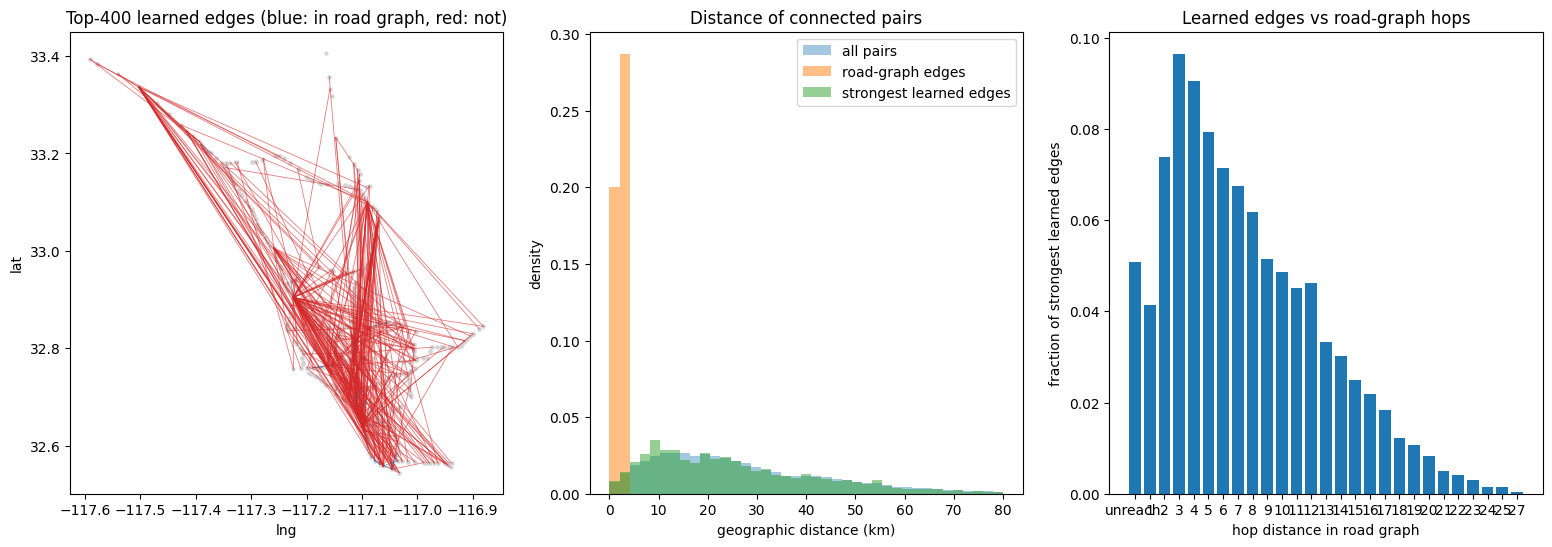

pairs with nonzero learned weight: 14302
Spearman(learned weight, -distance)     : 0.034549391447174116
Spearman(learned weight, train corr)    : 0.20801648128411565


In [56]:
ii, jj = top_adapt
W = A_learn.copy(); np.fill_diagonal(W, 0)
fig, axes = plt.subplots(1, 3, figsize=(19, 6))

ax = axes[0]
ax.scatter(LNG, LAT, s=4, c='lightgrey', zorder=1)
sel = slice(0, 400)
for a_, b_ in zip(ii[sel], jj[sel]):
    ax.plot([LNG[a_], LNG[b_]], [LAT[a_], LAT[b_]], lw=.6, zorder=2,
            color='tab:blue' if fixed_edge[a_, b_] else 'tab:red', alpha=.6)
ax.set_title('Top-400 learned edges (blue: in road graph, red: not)'); ax.set_xlabel('lng'); ax.set_ylabel('lat')

ax = axes[1]
bins = np.linspace(0, np.percentile(GEO, 99), 40)
fi, fj = np.where(Bin)
ax.hist(GEO[offdiag], bins=bins, density=True, alpha=.4, label='all pairs')
ax.hist(GEO[fi, fj], bins=bins, density=True, alpha=.5, label='road-graph edges')
ax.hist(GEO[ii, jj], bins=bins, density=True, alpha=.5, label='strongest learned edges')
ax.set_xlabel('geographic distance (km)'); ax.set_ylabel('density'); ax.legend(); ax.set_title('Distance of connected pairs')

ax = axes[2]
h = HOPS[ii, jj]; h = np.where(np.isinf(h), -1, h)
vals, cnts = np.unique(h, return_counts=True)
ax.bar([('unreach.' if v < 0 else str(int(v))) for v in vals], cnts / cnts.sum())
ax.set_xlabel('hop distance in road graph'); ax.set_ylabel('fraction of strongest learned edges'); ax.set_title('Learned edges vs road-graph hops')
savefig(fig, 'q6b_graph_analysis.png'); plt.show()

# rank correlation between learned weight and road weight / distance / training correlation over all pairs
from scipy.stats import spearmanr
mask_pairs = offdiag & (W > 0)
print('pairs with nonzero learned weight:', int(mask_pairs.sum()))
print('Spearman(learned weight, -distance)     :', spearmanr(W[mask_pairs], -GEO[mask_pairs]).correlation)
print('Spearman(learned weight, train corr)    :', spearmanr(W[mask_pairs], CORR[mask_pairs], nan_policy='omit').correlation)

# Question 7 – Reproducibility summary

In [57]:
CONFIG = {
    'seed': SEED, 'device': str(DEVICE), 'hardware': HW,
    'data': {'region': 'San Diego (LargeST, District 11)', 'nodes': N, 'years': [2020, 2021],
             'resampling': '5-min counts -> 15-min sums (3x mean of available)', 'input_steps': T_IN, 'horizon': T_OUT,
             'splits': {k: [str(TIMES[lo]), str(TIMES[hi - 1])] for k, (lo, hi) in SPLITS.items()},
             'norm': {'mean': MU, 'std': SIGMA, 'source': 'observed training values'}},
    'model': {'hidden_dim': HID, 'node_emb_dim': EMB, 'topk': TOPK, 'residual': RESIDUAL,
              'temporal_encoder': '2x temporal conv (k=3, same pad)+ReLU, Linear(d*8->d)', 'graph_layers': 1, 'head': 'MLP d->d->4',
              'fixed_norm': 'sym D^-1/2(A+I)D^-1/2' if SYMMETRIC else 'row D^-1(A+I)'},
    'training': {'loss': 'masked MAE (normalised)', 'optimizer': 'Adam', 'lr': LR, 'weight_decay': WD, 'batch': BATCH,
                 'max_epochs': EPOCHS, 'early_stopping_patience': PATIENCE, 'grad_clip': CLIP},
    'results': {k: {'val_MAE': RESULTS[k]['val']['MAE'], 'val_RMSE': RESULTS[k]['val']['RMSE'],
                    'test_MAE': RESULTS[k]['test']['MAE'], 'test_RMSE': RESULTS[k]['test']['RMSE'],
                    'test_MAE_h': RESULTS[k]['test']['MAE_h'], 'train_time_s': RESULTS[k]['train_time_s'],
                    'epochs_run': RESULTS[k]['epochs_run'], 'best_epoch': RESULTS[k]['best_epoch'],
                    'params': RESULTS[k]['n_params']} for k in order},
    'hybrid_alpha': MODELS['STGNN-Hybrid'].adj.alpha.item(),
}
with open(os.path.join(OUT_DIR, 'config_and_results.json'), 'w') as f:
    json.dump(CONFIG, f, indent=2, default=str)
for k, m in MODELS.items():
    torch.save(m.state_dict(), os.path.join(OUT_DIR, f'{k}.pt'))
print(json.dumps({k: v for k, v in CONFIG.items() if k != 'results'}, indent=2, default=str))
print('saved to', OUT_DIR, ':', sorted(os.listdir(OUT_DIR)))

{
  "seed": 42,
  "device": "cuda",
  "hardware": {
    "python": "3.13.16",
    "torch": "2.11.0+cu130",
    "platform": "Linux-6.18.55+-x86_64-with-glibc2.39",
    "processor": "x86_64",
    "cpu_count": 4,
    "device": "cuda",
    "ram_GB": 33.7,
    "gpu": "Tesla T4",
    "gpu_mem_GB": 15.6
  },
  "data": {
    "region": "San Diego (LargeST, District 11)",
    "nodes": 716,
    "years": [
      2020,
      2021
    ],
    "resampling": "5-min counts -> 15-min sums (3x mean of available)",
    "input_steps": 8,
    "horizon": 4,
    "splits": {
      "train": [
        "2020-01-01 00:00:00",
        "2020-12-31 23:45:00"
      ],
      "val": [
        "2021-01-01 00:00:00",
        "2021-03-31 23:45:00"
      ],
      "test": [
        "2021-04-01 00:00:00",
        "2021-12-31 23:45:00"
      ]
    },
    "norm": {
      "mean": 607.386474609375,
      "std": 483.7696838378906,
      "source": "observed training values"
    }
  },
  "model": {
    "hidden_dim": 32,
    "node_emb_

In [58]:
import os
import shutil
from IPython.display import FileLink, display

# Zip all files in /kaggle/working
output_zip = "/kaggle/working/all_files.zip"

shutil.make_archive(
    output_zip.replace(".zip", ""),
    'zip',
    '/kaggle/working'
)

# Download
display(FileLink(output_zip))

/kaggle/working/all_files.zip